In [ ]:
#PART A

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Load the Banknote dataset
# Columns: variance, skewness, curtosis, entropy, class
col_names = ['variance', 'skewness', 'curtosis', 'entropy', 'class']
df = pd.read_csv('data_banknote_authentication.txt', header=None, names=col_names)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nClass distribution:")
print(df['class'].value_counts())

# Prepare full feature matrix X and target y
X_full = df[['variance', 'skewness', 'curtosis', 'entropy']].values
y_full = df['class'].values

# Consistent 80-20 train-test split
X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42, stratify=y_full
)

# For Part A and Part B 2D plots: use first two features (variance, skewness)
X_train_2d = X_train_full[:, :2]
X_test_2d = X_test_full[:, :2]
feature_names_2d = ['variance', 'skewness']

Dataset shape: (1372, 5)

First 5 rows:
   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0

Class distribution:
class
0    762
1    610
Name: count, dtype: int64


In [8]:
class Node:
    """Represents a single decision node or leaf in the Decision Tree."""
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature          # Index of feature to split on
        self.threshold = threshold      # Threshold value for the split
        self.left = left                # Left child (Node)
        self.right = right              # Right child (Node)
        self.value = value              # Predicted class if this is a leaf node

    def is_leaf(self):
        return self.value is not None


class DecisionTreeScratch:
    def __init__(self, criterion='gini', max_depth=5, min_samples_split=2):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None

    def _impurity(self, y):
        """Calculates Gini impurity or Entropy for a set of labels y."""
        m = len(y)
        if m == 0:
            return 0.0
        _, counts = np.unique(y, return_counts=True)
        probs = counts / m

        if self.criterion == 'gini':
            return 1.0 - np.sum(probs ** 2)
        elif self.criterion == 'entropy':
            # Add 1e-12 to prevent log2(0)
            return -np.sum(probs * np.log2(probs + 1e-12))
        else:
            raise ValueError("Criterion must be 'gini' or 'entropy'")

    def _split(self, X_column, threshold):
        """Splits indices into left (<= threshold) and right (> threshold)."""
        left_idx = np.where(X_column <= threshold)[0]
        right_idx = np.where(X_column > threshold)[0]
        return left_idx, right_idx

    def _best_split(self, X, y):
        """Finds feature and threshold that maximize impurity reduction (Information Gain)."""
        best_gain = -1.0
        split_feat, split_thresh = None, None
        parent_impurity = self._impurity(y)
        n_samples, n_features = X.shape

        for feat in range(n_features):
            X_col = X[:, feat]
            thresholds = np.unique(X_col)
            
            # Optimization: evaluate midpoints between consecutive sorted unique values
            if len(thresholds) > 1:
                thresholds = (thresholds[:-1] + thresholds[1:]) / 2.0

            for thresh in thresholds:
                left_idx, right_idx = self._split(X_col, thresh)
                if len(left_idx) == 0 or len(right_idx) == 0:
                    continue

                # Weighted average child impurity
                n_left, n_right = len(left_idx), len(right_idx)
                child_impurity = (n_left / n_samples) * self._impurity(y[left_idx]) + \
                                 (n_right / n_samples) * self._impurity(y[right_idx])
                gain = parent_impurity - child_impurity

                if gain > best_gain:
                    best_gain = gain
                    split_feat = feat
                    split_thresh = thresh

        return split_feat, split_thresh

    def _build_tree(self, X, y, depth=0):
        """Recursive tree builder."""
        n_samples, _ = X.shape
        n_labels = len(np.unique(y))

        # Stopping criteria:
        # 1. Depth reached max_depth
        # 2. Pure node (only 1 class left)
        # 3. Not enough samples to split
        if (self.max_depth is not None and depth >= self.max_depth) or \
           n_labels == 1 or n_samples < self.min_samples_split:
            # Majority vote
            leaf_value = np.bincount(y).argmax()
            return Node(value=leaf_value)

        feat, thresh = self._best_split(X, y)
        # If no split gives positive gain, make leaf
        if feat is None:
            leaf_value = np.bincount(y).argmax()
            return Node(value=leaf_value)

        # Recursively build left and right subtrees
        left_idx, right_idx = self._split(X[:, feat], thresh)
        left_child = self._build_tree(X[left_idx], y[left_idx], depth + 1)
        right_child = self._build_tree(X[right_idx], y[right_idx], depth + 1)
        return Node(feature=feat, threshold=thresh, left=left_child, right=right_child)

    def fit(self, X, y):
        self.root = self._build_tree(X, y)

    def _traverse_tree(self, x, node):
        """Traverses the tree to classify a single sample x."""
        if node.is_leaf():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)

    def predict(self, X):
        return np.array([self._traverse_tree(x, self.root) for x in X])

    def print_tree(self, node=None, depth=0, feature_names=None):
        """Prints a human-readable visual hierarchy of the split rules."""
        if node is None:
            node = self.root
        indent = "  |  " * depth
        if node.is_leaf():
            print(f"{indent}--> Predict Class: {node.value}")
        else:
            feat_name = feature_names[node.feature] if feature_names else f"Feature_{node.feature}"
            print(f"{indent}[If {feat_name} <= {node.threshold:.3f}]")
            self.print_tree(node.left, depth + 1, feature_names)
            print(f"{indent}[If {feat_name} > {node.threshold:.3f}]")
            self.print_tree(node.right, depth + 1, feature_names)

In [4]:
# Train manual tree on the 2 features (variance and skewness) with max_depth=3 for visualization
dt_scratch_2d = DecisionTreeScratch(criterion='gini', max_depth=3)
dt_scratch_2d.fit(X_train_2d, y_train)

print("=== LEARNED MANUAL DECISION TREE SPLIT RULES ===")
dt_scratch_2d.print_tree(feature_names=feature_names_2d)

=== LEARNED MANUAL DECISION TREE SPLIT RULES ===
[If variance <= 0.765]
  |  [If skewness <= 5.161]
  |    |  [If variance <= 0.320]
  |    |    |  --> Predict Class: 1
  |    |  [If variance > 0.320]
  |    |    |  --> Predict Class: 1
  |  [If skewness > 5.161]
  |    |  [If variance <= -3.431]
  |    |    |  --> Predict Class: 1
  |    |  [If variance > -3.431]
  |    |    |  --> Predict Class: 0
[If variance > 0.765]
  |  [If variance <= 1.791]
  |    |  [If skewness <= 4.881]
  |    |    |  --> Predict Class: 0
  |    |  [If skewness > 4.881]
  |    |    |  --> Predict Class: 0
  |  [If variance > 1.791]
  |    |  [If variance <= 2.392]
  |    |    |  --> Predict Class: 0
  |    |  [If variance > 2.392]
  |    |    |  --> Predict Class: 0


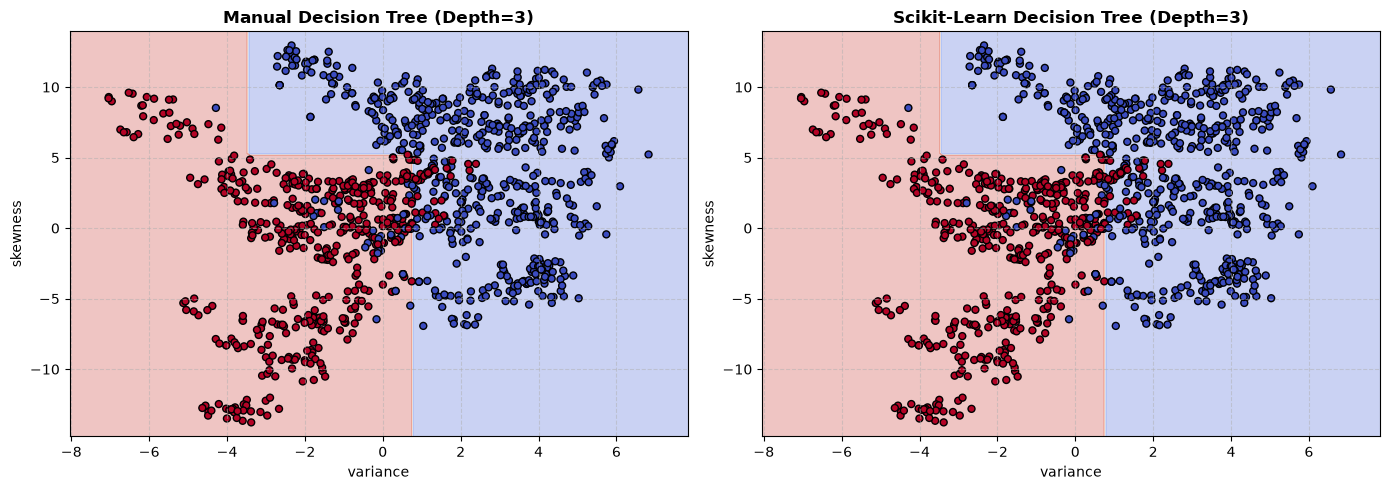

Manual Tree 2D Test Accuracy:      90.91%
Scikit-Learn Tree 2D Test Accuracy: 90.91%


In [5]:
def plot_decision_boundary(ax, model, X, y, title, feature_names):
    # Setup grid
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    
    # Predict for each grid point
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid_points)
    Z = Z.reshape(xx.shape)
    
    # Contour plot for boundary
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k', s=25)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(feature_names[0])
    ax.set_ylabel(feature_names[1])
    ax.grid(True, linestyle='--', alpha=0.5)

# Train Scikit-Learn DecisionTree for comparison
sk_tree_2d = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
sk_tree_2d.fit(X_train_2d, y_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_decision_boundary(axes[0], dt_scratch_2d, X_train_2d, y_train, "Manual Decision Tree (Depth=3)", feature_names_2d)
plot_decision_boundary(axes[1], sk_tree_2d, X_train_2d, y_train, "Scikit-Learn Decision Tree (Depth=3)", feature_names_2d)
plt.tight_layout()
plt.show()

# Quick accuracy check
acc_manual = np.mean(dt_scratch_2d.predict(X_test_2d) == y_test)
acc_sklearn = np.mean(sk_tree_2d.predict(X_test_2d) == y_test)
print(f"Manual Tree 2D Test Accuracy:      {acc_manual * 100:.2f}%")
print(f"Scikit-Learn Tree 2D Test Accuracy: {acc_sklearn * 100:.2f}%")

In [6]:
depths = [2, 3, 5, None]
criteria = ['gini', 'entropy']
results = []

for crit in criteria:
    for d in depths:
        # Manual
        dt_man = DecisionTreeScratch(criterion=crit, max_depth=d)
        dt_man.fit(X_train_2d, y_train)
        pred_man = dt_man.predict(X_test_2d)
        acc_man = accuracy_score(y_test, pred_man)

        # Sklearn
        dt_sk = DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=42)
        dt_sk.fit(X_train_2d, y_train)
        pred_sk = dt_sk.predict(X_test_2d)
        acc_sk = accuracy_score(y_test, pred_sk)

        results.append({
            'Criterion': crit,
            'Max Depth': 'None' if d is None else str(d),
            'Manual Accuracy': f"{acc_man * 100:.2f}%",
            'Sklearn Accuracy': f"{acc_sk * 100:.2f}%",
            'Match %': f"{np.mean(pred_man == pred_sk) * 100:.2f}%"
        })

df_tree_explore = pd.DataFrame(results)
print(df_tree_explore.to_string(index=False))

Criterion Max Depth Manual Accuracy Sklearn Accuracy Match %
     gini         2          87.64%           87.64% 100.00%
     gini         3          90.91%           90.91% 100.00%
     gini         5          93.09%           93.09% 100.00%
     gini      None          92.00%           92.00%  99.27%
  entropy         2          87.64%           87.64% 100.00%
  entropy         3          90.91%           90.91% 100.00%
  entropy         5          93.45%           93.45% 100.00%
  entropy      None          93.45%           93.45%  99.27%


In [9]:
#PART B

from sklearn.preprocessing import StandardScaler

# SVM is sensitive to feature scale because it computes geometric distances!
# Always fit scaler on train set, transform train and test sets.
scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

# Map labels from {0, 1} to {-1, +1}
y_train_svm = np.where(y_train == 0, -1, 1)
y_test_svm = np.where(y_test == 0, -1, 1)

print("Mapped unique labels:", np.unique(y_train_svm))

Mapped unique labels: [-1  1]


In [10]:
class LinearSVMScratch:
    def __init__(self, C=1.0, lr=0.001, n_iters=1000):
        self.C = C
        self.lr = lr
        self.n_iters = n_iters
        self.w = None
        self.b = None
        self.loss_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        # Initialize weights and bias to zeros
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.loss_history = []

        for iteration in range(self.n_iters):
            # Compute margin for all samples: y_i * (w^T x_i + b)
            margins = y * (np.dot(X, self.w) + self.b)
            
            # Identify margin violations: y_i * (w^T x_i + b) < 1
            violating_indices = np.where(margins < 1)[0]

            # Compute Hinge loss + Regularization loss
            hinge_loss = np.sum(1 - margins[violating_indices])
            reg_loss = 0.5 * np.dot(self.w, self.w)
            total_loss = reg_loss + (self.C / n_samples) * hinge_loss
            self.loss_history.append(total_loss)

            # Compute Subgradients
            # Regularization gradient
            dw = self.w.copy()
            db = 0.0

            # Add gradient from violating samples
            if len(violating_indices) > 0:
                dw -= (self.C / n_samples) * np.dot(y[violating_indices], X[violating_indices])
                db -= (self.C / n_samples) * np.sum(y[violating_indices])

            # Gradient descent update
            self.w -= self.lr * dw
            self.b -= self.lr * db

    def decision_function(self, X):
        return np.dot(X, self.w) + self.b


    def predict(self, X):
        # sign(w^T x + b) mapped to {-1, +1}
        return np.where(self.decision_function(X) >= 0, 1, -1)

Number of margin-violating samples in training set: 525 / 1097


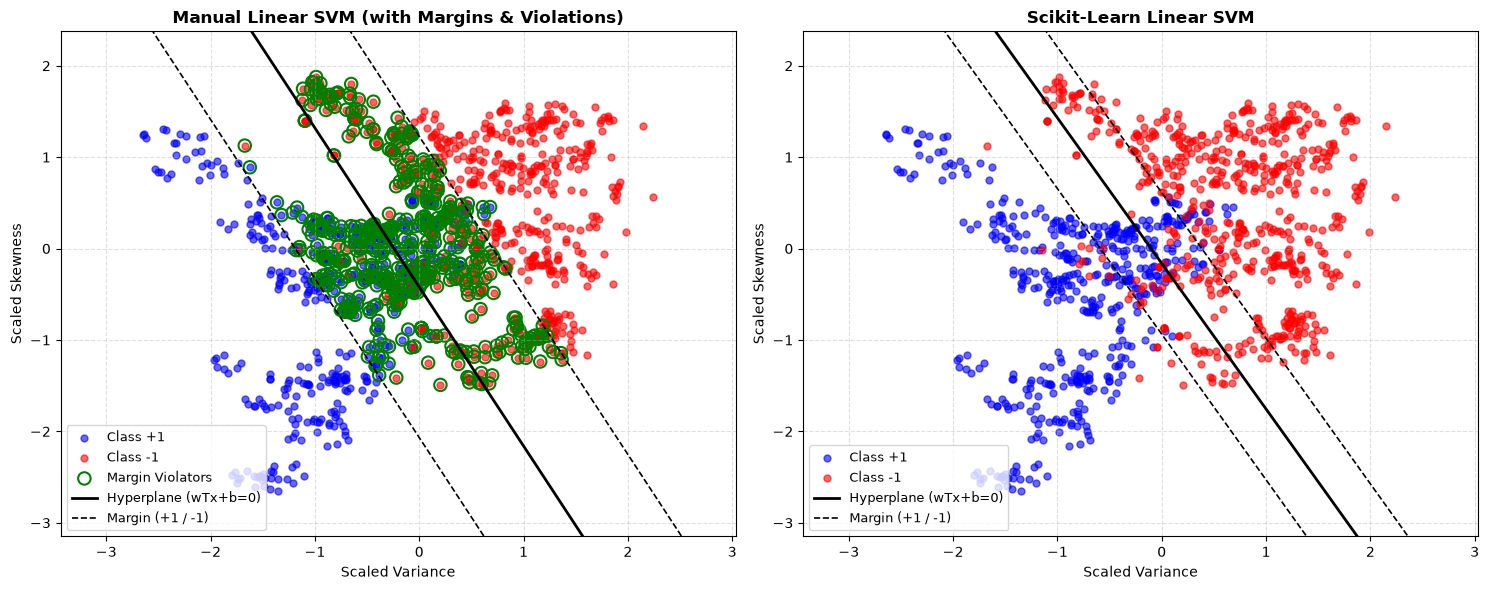

Manual Linear SVM Test Accuracy:      88.73%
Scikit-Learn Linear SVM Test Accuracy: 87.64%


In [11]:
from sklearn.svm import SVC

# Train Manual SVM
svm_manual_2d = LinearSVMScratch(C=10.0, lr=0.01, n_iters=2000)
svm_manual_2d.fit(X_train_2d_scaled, y_train_svm)

# Train Scikit-Learn Linear SVM for comparison
svm_sk_2d = SVC(kernel='linear', C=10.0)
svm_sk_2d.fit(X_train_2d_scaled, y_train_svm)

# Identify margin-violating samples for the manual model
train_margins = y_train_svm * svm_manual_2d.decision_function(X_train_2d_scaled)
violators_idx = np.where(train_margins < 1.0)[0]

print(f"Number of margin-violating samples in training set: {len(violators_idx)} / {len(y_train_svm)}")

def plot_svm_boundary(ax, w, b, X, y, title, violators=None):
    # Scatter data points
    ax.scatter(X[y == 1, 0], X[y == 1, 1], color='blue', label='Class +1', s=25, alpha=0.6)
    ax.scatter(X[y == -1, 0], X[y == -1, 1], color='red', label='Class -1', s=25, alpha=0.6)

    # Highlight margin violators if provided
    if violators is not None:
        ax.scatter(X[violators, 0], X[violators, 1], s=80, facecolors='none',
                   edgecolors='green', linewidth=1.5, label='Margin Violators')

    # Plot separating hyperplane (w0*x0 + w1*x1 + b = 0) => x1 = (-w0*x0 - b) / w1
    x0_vals = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 200)
    
    # Decision line: w^T x + b = 0
    decision_line = (-w[0] * x0_vals - b) / w[1]
    # Margin +1: w^T x + b = 1
    margin_pos = (-w[0] * x0_vals - b + 1.0) / w[1]
    # Margin -1: w^T x + b = -1
    margin_neg = (-w[0] * x0_vals - b - 1.0) / w[1]

    ax.plot(x0_vals, decision_line, 'k-', linewidth=2, label='Hyperplane (wTx+b=0)')
    ax.plot(x0_vals, margin_pos, 'k--', linewidth=1.2, label='Margin (+1 / -1)')
    ax.plot(x0_vals, margin_neg, 'k--', linewidth=1.2)

    ax.set_ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Scaled Variance')
    ax.set_ylabel('Scaled Skewness')
    ax.legend(loc='lower left', fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.4)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot Manual SVM
plot_svm_boundary(axes[0], svm_manual_2d.w, svm_manual_2d.b, X_train_2d_scaled,
                  y_train_svm, "Manual Linear SVM (with Margins & Violations)", violators=violators_idx)

# Plot Scikit-learn Linear SVM
plot_svm_boundary(axes[1], svm_sk_2d.coef_[0], svm_sk_2d.intercept_[0], X_train_2d_scaled,
                  y_train_svm, "Scikit-Learn Linear SVM")

plt.tight_layout()
plt.show()

# Test Accuracy
acc_svm_man = np.mean(svm_manual_2d.predict(X_test_2d_scaled) == y_test_svm)
acc_svm_sk = np.mean(svm_sk_2d.predict(X_test_2d_scaled) == y_test_svm)
print(f"Manual Linear SVM Test Accuracy:      {acc_svm_man * 100:.2f}%")
print(f"Scikit-Learn Linear SVM Test Accuracy: {acc_svm_sk * 100:.2f}%")

--- STUDY 1: EFFECT OF REGULARIZATION C ---
C =   0.1 | Test Acc: 58.91% | Margin Width (2/||w||): 23.816 | Margin Violators: 1097
C =   1.0 | Test Acc: 86.55% | Margin Width (2/||w||): 3.563 | Margin Violators: 926
C =  10.0 | Test Acc: 88.73% | Margin Width (2/||w||): 1.642 | Margin Violators: 526
C = 100.0 | Test Acc: 88.36% | Margin Width (2/||w||): 1.026 | Margin Violators: 355


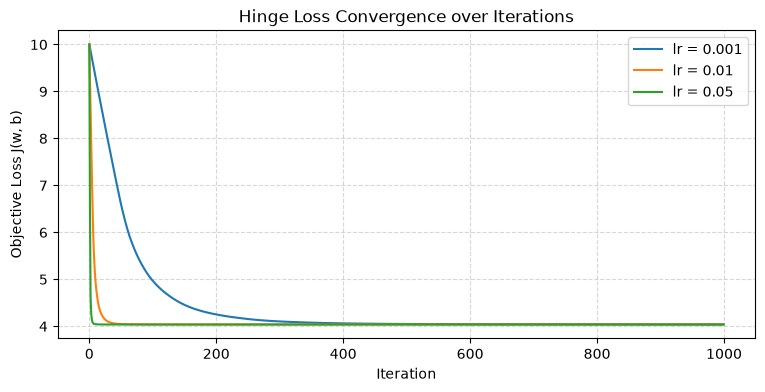

In [12]:
# Study 1: Effect of Regularization C
C_values = [0.1, 1.0, 10.0, 100.0]
print("--- STUDY 1: EFFECT OF REGULARIZATION C ---")
for c in C_values:
    model = LinearSVMScratch(C=c, lr=0.01, n_iters=1500)
    model.fit(X_train_2d_scaled, y_train_svm)
    acc = accuracy_score(y_test_svm, model.predict(X_test_2d_scaled))
    # Number of violators
    violators = np.sum(y_train_svm * model.decision_function(X_train_2d_scaled) < 1.0)
    margin_width = 2.0 / np.linalg.norm(model.w)
    print(f"C = {c:5.1f} | Test Acc: {acc*100:.2f}% | Margin Width (2/||w||): {margin_width:.3f} | Margin Violators: {violators}")

# Study 2: Loss Curve across Iterations for different Learning Rates
lrs = [0.001, 0.01, 0.05]
plt.figure(figsize=(9, 4))
for lr in lrs:
    model = LinearSVMScratch(C=10.0, lr=lr, n_iters=1000)
    model.fit(X_train_2d_scaled, y_train_svm)
    plt.plot(model.loss_history, label=f"lr = {lr}")

plt.title("Hinge Loss Convergence over Iterations")
plt.xlabel("Iteration")
plt.ylabel("Objective Loss J(w, b)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

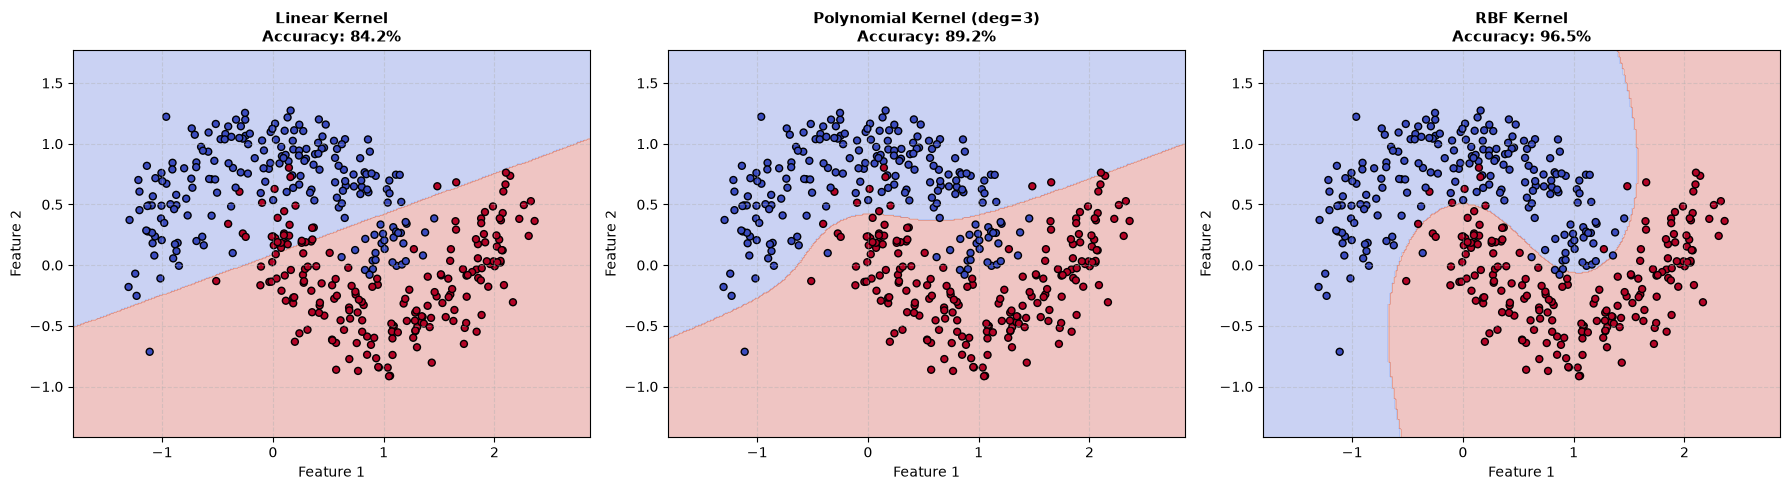

In [13]:
#PART C

from sklearn.datasets import make_moons

# 1. Generate synthetic 2D nonlinear dataset
X_moons, y_moons = make_moons(n_samples=400, noise=0.20, random_state=42)

# 2. Train 3 Scikit-learn SVM models
kernels = ['linear', 'poly', 'rbf']
svm_models = {
    'Linear Kernel': SVC(kernel='linear', C=1.0),
    'Polynomial Kernel (deg=3)': SVC(kernel='poly', degree=3, C=1.0),
    'RBF Kernel': SVC(kernel='rbf', C=1.0, gamma='scale')
}

# 3. Plot Decision Boundaries side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Meshgrid for plotting
x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid_points = np.c_[xx.ravel(), yy.ravel()]

for ax, (title, clf) in zip(axes, svm_models.items()):
    clf.fit(X_moons, y_moons)
    Z = clf.predict(grid_points).reshape(xx.shape)
    acc = accuracy_score(y_moons, clf.predict(X_moons))
    
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap=plt.cm.coolwarm, edgecolors='k', s=25)
    ax.set_title(f"{title}\nAccuracy: {acc*100:.1f}%", fontsize=11, fontweight='bold')
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


In [14]:
#PART D

# Scale all 4 features for SVMs
scaler_full = StandardScaler()
X_train_full_scaled = scaler_full.fit_transform(X_train_full)
X_test_full_scaled = scaler_full.transform(X_test_full)

# Setup models dictionary
# Note: For SVM from scratch, we use y in {-1, 1}
models = {
    "Manual Decision Tree": {
        "model": DecisionTreeScratch(criterion='gini', max_depth=5),
        "scaled": False, "svm_labels": False
    },
    "Scikit-Learn Decision Tree": {
        "model": DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42),
        "scaled": False, "svm_labels": False
    },
    "Manual Linear SVM": {
        "model": LinearSVMScratch(C=10.0, lr=0.01, n_iters=2000),
        "scaled": True, "svm_labels": True
    },
    "Scikit-Learn Linear SVM": {
        "model": SVC(kernel='linear', C=10.0),
        "scaled": True, "svm_labels": True
    },
    "Scikit-Learn RBF SVM": {
        "model": SVC(kernel='rbf', C=10.0, gamma='scale'),
        "scaled": True, "svm_labels": True
    }
}

benchmark_results = []

for name, cfg in models.items():
    clf = cfg["model"]
    
    # Choose features (scaled for SVM, unscaled for Tree)
    X_tr = X_train_full_scaled if cfg["scaled"] else X_train_full
    X_te = X_test_full_scaled if cfg["scaled"] else X_test_full
    
    # Choose labels ({0, 1} for Tree, {-1, +1} for SVM)
    y_tr = y_train_svm if cfg["svm_labels"] else y_train
    y_te = y_test_svm if cfg["svm_labels"] else y_test
    
    # Measure Training Time
    start_train = time.perf_counter()
    clf.fit(X_tr, y_tr)
    train_time = time.perf_counter() - start_train
    
    # Measure Prediction Time
    start_pred = time.perf_counter()
    y_pred = clf.predict(X_te)
    pred_time = time.perf_counter() - start_pred
    
    # If SVM labels, map predictions back to {0, 1} for uniform metric calculation
    if cfg["svm_labels"]:
        y_pred_eval = np.where(y_pred == -1, 0, 1)
        y_te_eval = np.where(y_te == -1, 0, 1)
    else:
        y_pred_eval = y_pred
        y_te_eval = y_te
        
    acc = accuracy_score(y_te_eval, y_pred_eval)
    prec = precision_score(y_te_eval, y_pred_eval)
    rec = recall_score(y_te_eval, y_pred_eval)
    f1 = f1_score(y_te_eval, y_pred_eval)
    
    benchmark_results.append({
        "Model": name,
        "Accuracy": f"{acc*100:.2f}%",
        "Precision": f"{prec*100:.2f}%",
        "Recall": f"{rec*100:.2f}%",
        "F1-Score": f"{f1*100:.2f}%",
        "Train Time (ms)": f"{train_time * 1000:.2f}",
        "Inference Time (ms)": f"{pred_time * 1000:.2f}"
    })

comparison_df = pd.DataFrame(benchmark_results)
print("\n=== FINAL 4-FEATURE MODEL COMPARISON ===")
print(comparison_df.to_string(index=False))


=== FINAL 4-FEATURE MODEL COMPARISON ===
                     Model Accuracy Precision  Recall F1-Score Train Time (ms) Inference Time (ms)
      Manual Decision Tree   99.27%    98.39% 100.00%   99.19%          738.51                0.22
Scikit-Learn Decision Tree   99.27%    98.39% 100.00%   99.19%            1.74                0.13
         Manual Linear SVM   97.09%    93.85% 100.00%   96.83%           61.17                0.02
   Scikit-Learn Linear SVM   98.55%    96.83% 100.00%   98.39%            9.26                0.82
      Scikit-Learn RBF SVM  100.00%   100.00% 100.00%  100.00%            3.04                0.65
